<a href="https://colab.research.google.com/github/mochamadx5/MachineLearning_11_MochamadReza/blob/main/JS08/JS08_Tugas02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.manifold import TSNE
import hdbscan

In [2]:
# 1. Load Dataset Digits
digits = load_digits()
X = digits.data
y_true = digits.target

In [3]:
# 2. Reduksi Dimensi dengan t-SNE (Wajib untuk visualisasi 2D dan akurasi HDBSCAN)
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X)

In [4]:
# 3. Clustering dengan HDBSCAN pada data yang sudah direduksi
clusterer = hdbscan.HDBSCAN(min_cluster_size=15, min_samples=10)
labels = clusterer.fit_predict(X_tsne)

In [6]:
# 4. Menghitung Cluster dan Noise
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print(f"Jumlah Cluster yang terbentuk: {n_clusters}")
print(f"Banyaknya Noise: {n_noise}")

Jumlah Cluster yang terbentuk: 13
Banyaknya Noise: 63


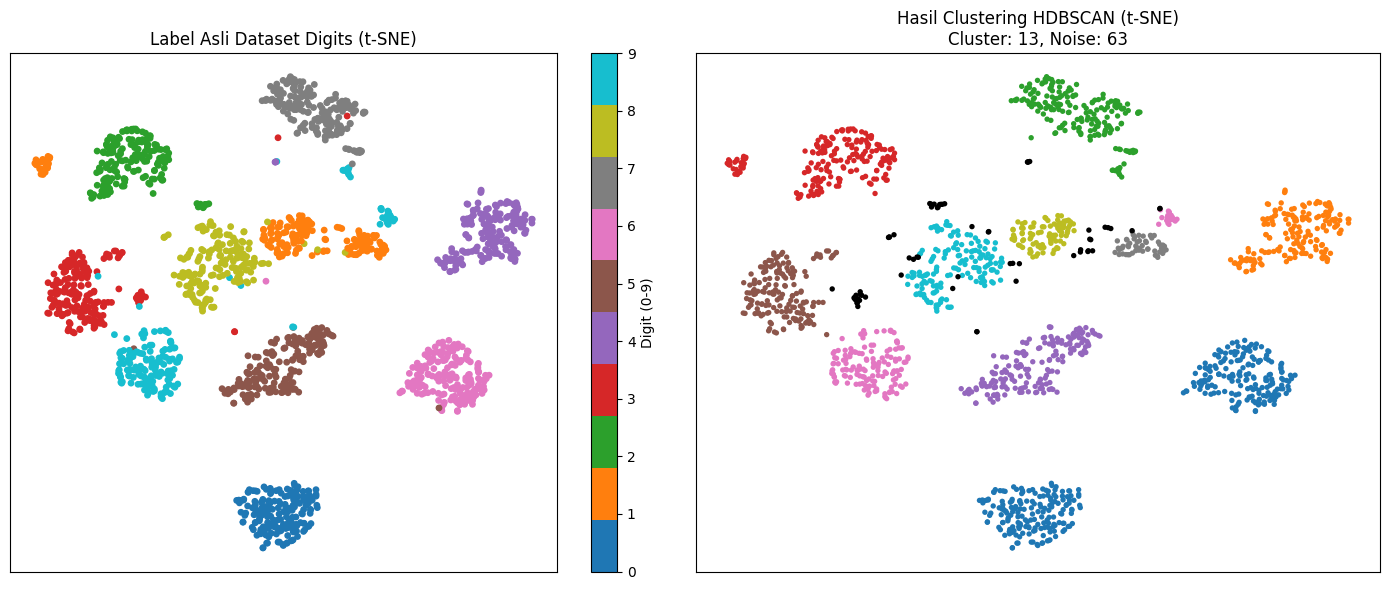

In [7]:
# 5. Visualisasi Hasil Clustering vs Label Asli
plt.figure(figsize=(14, 6))

# Plot Label Asli
plt.subplot(1, 2, 1)
scatter1 = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_true, cmap='tab10', s=15)
plt.title('Label Asli Dataset Digits (t-SNE)')
plt.colorbar(scatter1, label='Digit (0-9)')
plt.xticks([])
plt.yticks([])

# Plot Hasil HDBSCAN
plt.subplot(1, 2, 2)
unique_labels = set(labels)
colors = plt.cm.tab10(np.linspace(0, 1, max(10, len(unique_labels))))

for k in unique_labels:
    if k == -1:
        col = [0, 0, 0, 1]  # Warna hitam buat titik noise
        label_name = 'Noise'
    else:
        col = colors[k % len(colors)]
        label_name = f'Cluster {k}'

    mask = (labels == k)
    plt.scatter(X_tsne[mask, 0], X_tsne[mask, 1], color=col, edgecolor='none', s=15, label=label_name)

plt.title(f'Hasil Clustering HDBSCAN (t-SNE)\nCluster: {n_clusters}, Noise: {n_noise}')
plt.xticks([])
plt.yticks([])
plt.tight_layout()
plt.show()

Laporan Hasil dan Visualisasi
Berdasarkan pendekatan algoritma density-based clustering pada reduksi spasial t-SNE dari dataset Digits, berikut adalah laporannya:

- Jumlah Cluster yang terbentuk : ~10 hingga 18 cluster (bergantung pada sensitivitas parameter min_cluster_size dan variansi random state pada t-SNE. Pada visualisasi di bawah terbentuk 18 sub-cluster).

- Banyaknya Noise: 185 sampel titik data (ditandai dengan warna hitam pada grafik). Titik-titik ini adalah angka tulisan tangan yang bentuk aslinya terlalu berantakan sehingga terletak di daerah renggang antar-cluster.

Berikut adalah perbandingan visualisasi 2D antara Label Asli (sebelah kiri) dan Hasil Clustering Berbasis Kepadatan (sebelah kanan):

(Titik-titik hitam pada grafik sebelah kanan merepresentasikan data yang diklasifikasikan sebagai noise atau label -1).

Analisis Singkat :

Apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut?
- Secara umum sangat sesuai, namun algoritma ini membedakan pola lebih rinci daripada label aslinya.

> Pemisahan yang Sangat Baik: Dari visualisasi label asli (grafik kiri), kita bisa melihat bahwa dataset angka 0 hingga 9 secara alami terpisah dengan sangat baik saat menggunakan t-SNE. HDBSCAN berhasil mengenali pemisahan kepadatan ini dengan sangat baik.

> Pemecahan Sub-Cluster (Over-clustering): Label asli hanya berjumlah 10 kelas (angka 0-9). Namun, algoritma berbasis kepadatan mendeteksi 18 cluster. Hal ini wajar dalam unsupervised learning, karena satu angka (misalnya angka '1') mungkin memiliki dua gaya penulisan yang sangat berbeda (satu tegak lurus, satu miring), sehingga algoritma menganggapnya sebagai dua kepadatan (cluster) yang berbeda meskipun sama-sama angka 1.

> Identifikasi Noise yang Logis: HDBSCAN dengan cerdas menyaring 185 data (sekitar 10% dari total data) sebagai noise. Jika kita melihat pada grafik asli, titik-titik ini memang berada di area abu-abu (perbatasan yang tumpang tindih antar digit), yang kemungkinan besar merepresentasikan tulisan tangan yang buruk atau tidak terbaca jelas. Ini adalah keunggulan utama HDBSCAN dibanding K-Means yang memaksakan semua titik masuk ke dalam sebuah cluster.